# Solution 01 - Function Generator 

## Initial Python Hints

* `1j` can be used as an imaginary number in python code

* The `numpy` library contains a variety of useful functions, such as:
 * [`arange`](https://numpy.org/doc/stable/reference/generated/numpy.arange.html),
 * [`zeros`](https://numpy.org/doc/stable/reference/generated/numpy.zeros.html),
 * [`pi`](https://numpy.org/doc/stable/reference/constants.html?highlight=pi#numpy.pi),
 * [`sin`](https://numpy.org/doc/stable/reference/generated/numpy.sin.html),
 * [`mod`](https://numpy.org/doc/stable/reference/generated/numpy.mod.html),
 * [`abs`](https://numpy.org/doc/stable/reference/generated/numpy.absolute.html),
 * [`exp`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html),
 * [`real`](https://numpy.org/doc/stable/reference/generated/numpy.real.html),
 * [`imag`](https://numpy.org/doc/stable/reference/generated/numpy.imag.html),
 * [`vectorize`](https://numpy.org/doc/stable/reference/generated/numpy.vectorize.html)

We can plot graphs using the `matplotlib.pyplot` library. For most of these exercises, [`stem`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.stem.html) will be most appropriate, but [`plot`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.plot.html) is also available. We can display multiple graphs using [`subplot`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.subplot.html).

Here's an example of some of these libraries:

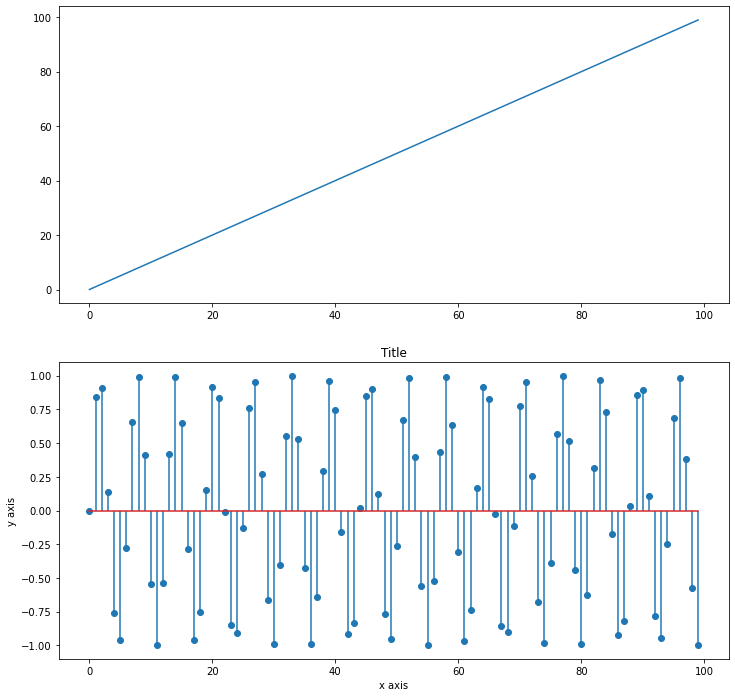

In [1]:
#import the libraries
import numpy as np
import matplotlib.pyplot as plt

#create a numpy array containing the integers 0...99
x = np.arange(100) 
#apply a sine function to the array
y = np.sin(x) 

#create a figure to house our graphs
plt.figure(figsize=(12,12))

#first a regular plot
ax1 = plt.subplot(2,1,1)
ax1.plot(x)

#second a stem plot with optional title and labels
ax2 = plt.subplot(2,1,2)
ax2.set_title('Title')
ax2.set_xlabel("x axis")
ax2.set_ylabel("y axis")
ax2.stem(y, use_line_collection = True);

<a id='task_function_generator'></a>
<div class="alert alert-block alert-success">
<strong>Learning Objectives</strong><br>
<ul>
<li>Demonstrate the formal definition of a signal as a mathematical function.
</li>
    
<li>visualise (and hear) the effect of the input parameters on the final output
</li>
    
<li>gain a better understanding of digital signals by visualising a discretely sampled signal.
</li>
    
<li>understand that the interaction between frequency and sampling rate can result in a change of period between continuous and discrete signals
</li>

</ul>
</div>

## Background Theory

"Real world" audio signals are generally considered to vary continuously as a function of time. However, in order to model signals as part of a digital system, it is necessary to quantize signals into discrete forms, usually by sampling at equidistant intervals. If we were to sample a signal once every $0.125$ seconds or $8$ times a second, the resulting discrete signal is said to have a **sampling interval** of $T_s=0.125\textrm{s}$ and a **sampling rate** of $f_s=8 \textrm{ Hz}$. 

A [function generator](https://en.wikipedia.org/wiki/Function_generator "Click for more details on Wikipedia") shall be programmed which generates a signal of frequency $f_0$ at a sampling frequency of $f_s$. This generator shall be able to generate a sinusoidal and a sawtooth signal. For a time-continuous system it is common to use the [angular frequency](https://en.wikipedia.org/wiki/Angular_frequency "Click for more details on Wikipedia") $\omega_0 = 2 \pi f_0$. Thus, a time continuous sine signal is given by

$$
x_\mathrm{sin,c}(t) = \sin \left( \omega_0 \cdot t \right).
$$

For a time-discrete system the sinusoidal signal is sampled with periods of the length $T_s = 1/f_s$, such that the time $t=T_s \cdot k$ can be written in terms of time-discrete indices $k =0, 1 , 2, ...$. By this, we obtain

$$
x_\mathrm{sin}[k]= \left. x_\mathrm{sin,c}(t) \right|_{t=kT_s} 
= \sin\left( \omega_0 \cdot T_s \cdot k \right).
$$

For time-discrete systems it makes sense to introduce the [normalised angular frequency](https://en.wikipedia.org/wiki/Normalized_frequency_(signal_processing) "Click for more details on Wikipedia") $\Omega_0$, which is a quantity without any unit.

$$
\begin{array}{rcl}
\Omega_0 & := & \omega_0 \cdot T_s \\
         & =  & 2 \pi f_0 \cdot T_s \\
         & =  & 2 \pi f_0 / f_s \\
\end{array}
$$

This definition will be used throughout the further exercises, since it allows handling of digital systems without the need to defibe a sampling frequency. It follows that

$$
x_\mathrm{sin}[k] = \sin \left( \Omega_0 \cdot k \right).
$$

<a id='task_function_generator_task1a_sine'></a>
<div class="alert alert-block alert-info">
<strong>Task 1.a): Sine signal</strong><br>
<ul>
<li>Create a vector <code>x</code> for samples ranging from $k=0$ to $k=60$ samples of a sinusoidal signal with the frequency $f_0=400 \,\mathrm{Hz}$ at a sampling frequency of $f_s = 8\,\mathrm{kHz}$. 
    <ul>
        <li>
            In order to do so initialize a coefficient vector <code>k=[0, 1, ..., 60]</code>, which represents the time index of the sampled signal $x[k]$.
        </li>
        <li>
            Make use of <code>Numpy</code>'s <code>sin()</code>-function. 
        </li>
    </ul>
</li>
    
<li>Display the signal with the help of the function <code>stem()</code> from the <a href="https://matplotlib.org/"><code>Matplotlib</code></a> library.
</li>
    
<li> A continuous sine signal is a repeating signal with a period of  $1/f_0$. How many samples are there in each period of the new discrete signal, i.e. what is the period of the sampled signal?
</li>

</ul>
</div>

<a id='exercise_function_generator_sine_hint'></a>
<div class="alert alert-block alert-warning">
<strong>Implementation Hints:</strong><br>
    
```python 
k=np.arange(0,59)      # creating vector of coefficients
Omega0=2*np.pi*f0/fs   # defines Omega
xsin=sin(Omega0*k)     # elementwise calculation 
                       # of the signal
stem(xsin)             # plotting xsin 
stem(k,xsin)           # plotting xsin over its 
                       # correct indices vector k
```
</div>

In [7]:
# Let's do some necessary and nice-to-have imports
%matplotlib inline
import matplotlib.pyplot as plt  # plotting
import seaborn as sns; sns.set() # styling
import numpy as np               # math

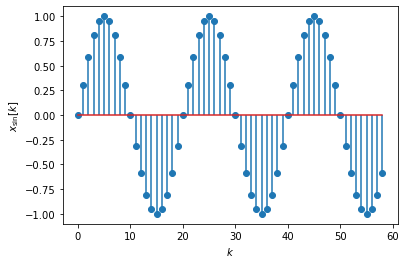

In [3]:
fs=8000        # set the sampling-frequency

###### Part a:  sinusodial #####
# Generating the signal vector #        
k = np.arange(0,60)   # generate a vector of length 61 with entries from 0 to 59
f0=400                # this is the signal-frequency
Omega0=2*np.pi*f0/fs  # we need the normalized frequency
xsin=np.sin(Omega0*k) # this is the vector wit the values of the sinusodial signal

# graphical output #
plt.figure()       # open new figure
plt.stem(k,xsin,                      # discrete plotting of the signal; k is the vector with the values
         use_line_collection = True) # on the  x-axis, xsin are the signal-values on the y axis
plt.xlabel('$k$')                    # place a label on the x-axis
plt.ylabel('$x_{\mathrm{sin}}[k]$'); # place a label on the y-axis

> The period of the continuous signal $x_{\sin,c}(t) = \sin (2\pi f_0 \cdot t)$ is $T_0 = 1/f_0$. Since the number of samples per period of the time continuous signal is an integer, the discrete signal has to have a period of

$$
\begin{align}
k_p &= T_0/T_s\\
&= f_s/f_0 \\
&\Downarrow f_s = 8 \textrm{ kHz}, f_0 = 400 \textrm{ Hz} \\
&= 20
\end{align}
$$

> samples.

<a id='task_function_generator_task1b'></a>
<div class="alert alert-block alert-info">
<strong>Task 1.b)</strong><br>
<ul>
<li> Change the frequency of the sampled sinusoidal signal to $f_0 = 960 \,\mathrm{ Hz}$ and the plot the resulting signal again.
</li>
    
<li> How many samples are there in each period of the discrete signal now?
</li>

</ul>
</div>

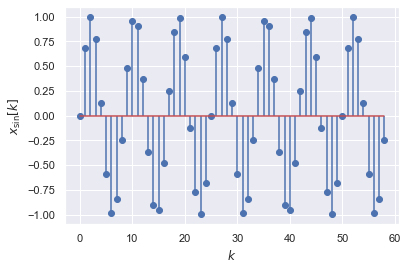

In [4]:
#####  Part b: different frequency   #####
f0=960                # this is the signal-frequency
Omega0=2*np.pi*f0/fs  # we need the normalized frequency
xsin=np.sin(Omega0*k) # this is the vector wit the values of the sinusodial signal

# graphical output 
plt.figure()       # open new figure
plt.stem(k,xsin);  # diskrete plotting of the signal; k is the vbector with the values
                   # on the  x-axis, xsin are the signal-values on the y axis
plt.xlabel('$k$')                    # place a label on the x-axis
plt.ylabel('$x_{\mathrm{sin}}[k]$'); # place a label on the y-axis


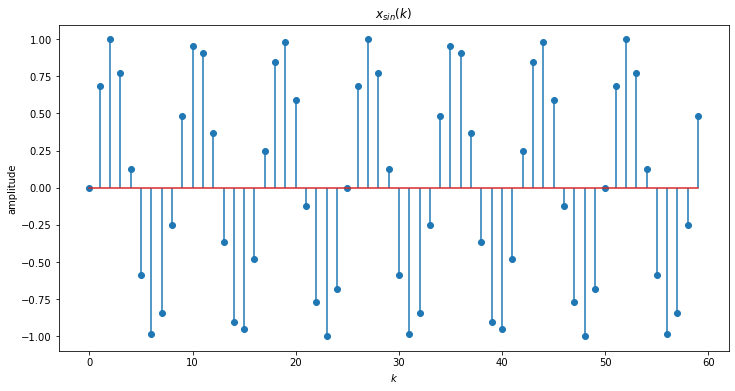

In [4]:
f0 = 960                      # frequency
fA = 8000                     # sampling rate
k = np.arange(60)             # time index
naf0 = 2 * np.pi * f0 / fA    # normalised angular frequency
x = np.sin(naf0 * k)          # sine signal

plt.figure(figsize=(12,6))
ax1 = plt.subplot()
ax1.set_title('$x_{sin}(k)$')
ax1.set_xlabel("$k$")
ax1.set_ylabel("amplitude")
ax1.stem(x, use_line_collection = True);

> Trying the same method as before gets us

$$
\begin{align}
k_p &= T_0/T_s\\
&= f_s/f_0 \\
&\Downarrow f_s = 8 \textrm{ kHz}, f_0 = 960 \textrm{ Hz} \\
&= 8.\bar{3}
\end{align}
$$

> samples. Since this isn't an integer this means that our samples do not cleanly fit within the original period, that the period of the discrete signal no longer corresponds to the period of the continuous signal.
> 
> The period of the discrete signal is only obtained after

$$
\begin{align}
k_p &= L \cdot T_0/T_s\\
&= L \cdot f_s/f_0 \\
&\Downarrow f_s = 8 \textrm{ kHz}, f_0 = 960 \textrm{ Hz} \\
&= L \cdot 8.\bar{3}
\end{align}
$$

>samples, Where $L$ indicates the fewest number of periods of the continuous signal required to obtain an integer number of samples, after which the periodicity of the discrete sampled signal is established. Since $\frac{1}{0.\bar{3}} = 3$ we end up at

$$
\begin{align}
k_p &= L \cdot 8.\bar{3} \\ 
&\Downarrow L = 3 \\
&= 25
\end{align}
$$

> samples. We can see this by looking at our plot where the amplitude starts at $0$ and hits $0$ again at samples $25$ and $50$. 

<a id='task_function_generator_task1c'></a>
<div class="alert alert-block alert-info">
<strong>Task 1.c) Sawtooth signal</strong><br>

Now generate a sawtooth signal with the frequency $f_0 = 960 \textrm{ Hz}$ at a sampling rate of $f_s = 8 \,\mathrm{kHz}$. The sawtooth signal should cover the amplitude range $0...1$. A sawtooth signal can be generated using a modulus function:

$$x_{saw}(k) = \mathrm{mod}(\frac{f_0}{f_s} \cdot k,1) $$
    
You can normalise the signal frequency $f_0$ to the sampling rate $f_s$ in the same way as the normalisation of the sinusoidal signal. Note, however, that unlike the $2\pi$ periodicity of the $\sin()$ function, you can set the period of the $\mathrm{mod}()$ function yourself. Plot the sawtooth signal and compare it with the sine signal.

</div>

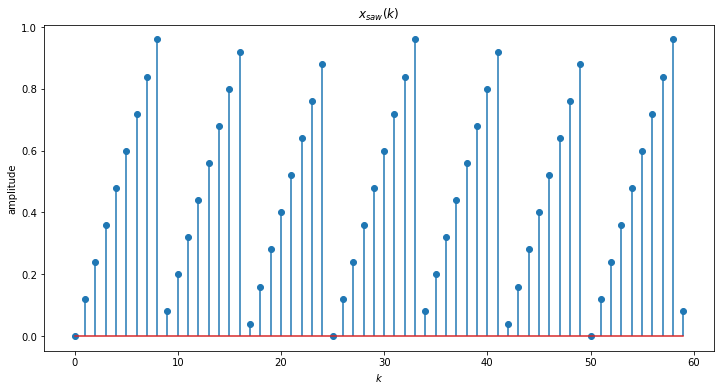

In [5]:
f0 = 960                      # frequency
fA = 8000                     # sampling rate
k = np.arange(60)             # time index
x = np.mod((f0 / fA) * k,1)   # sawtooth signal

plt.figure(figsize=(12,6))
ax1 = plt.subplot()
ax1.set_title('$x_{saw}(k)$')
ax1.set_xlabel("$k$")
ax1.set_ylabel("amplitude")
ax1.stem(x, use_line_collection = True);

> The period of the discrete signal - just like the sine signal from Task b) - remains $k_p = 25$.

<a id='task_function_generator_task1d'></a>
<div class="alert alert-block alert-info">
<strong>Task 1.d)</strong><br>
Generate and sine and a sawtooth signal, each with a frequency $f_0 = 1 \,\mathrm{kHz}$ and a sample rate of $f_s = 8 \,\mathrm{kHz}$. You can listen to your signals using the code

```python
import IPython.display as ipd
ipd.Audio(your_signal,rate=8000)
```

Have your signal play for $d = 2$ seconds each. How many samples are necessary for  this?
</div>

In [7]:
import IPython.display as ipd

f0 = 1000                           # frequency
fs = 8000                           # sampling rate
d = 2                               # time
k = np.arange(fs*d)                 # time index
naf0 = 2 * np.pi * f0 / fs          # normalised angular frequency
x_sin = np.sin(naf0 * k)            # sine signal
x_saw = np.mod((f0 / fs) * k,1)     # sawtooth signal

ipd.Audio(x_sin,rate=8000)

In [8]:
ipd.Audio(x_saw,rate=8000)

> For a playback time of $d = 2$ seconds, we need $k = f_0 \cdot d$ or $16000$ samples.

*  Change the frequency of the sampled sinusoidal signal to $f_0=960$~Hz and display the resulting signal again by using `stem()`

  What is the period of the sampled signal now?
  
* Create a sawtooth signal having a frequency of $f_0=960$ Hz at a sampling frequency of $f_s=8$ kHz.
  
  The sawtooth signal should be in the amplitude range between $0... 1$.
  
  Use the Matlab function `mod()`.
  
  The normalisation of the signal frequency $f_0$ to the sampling frequency $f_s$ can be calculated as for the sine signal.
  
  Please note that the period duration 
   Beachten Sie jedoch, da"s Sie die Periodendauer der `mod()`
   Funktion im Gegensatz zu der $2\pi$-Periodiztit"at der `sin()`-Funktion selbst
   festlegen.

   Stellen Sie das S"agezahnsignal mit `stem()` dar und  vergleichen Sie es
   mit der Sinussignal. Stimmt die Signalfrequenz?


*  Erzeugen Sie jeweils ein Vektor mit einem Sinus- und einem S"agezahnsignal
   mit $f_0=1$ kHz bei einer Abtastfrequenz von $f_s=8$ kHz.

   Die Signale sollen "uber eine Soundkarte ausgegeben werden und
   daher eine Abspieldauer von $d=2 \mathrm{s}$ haben.
   
   Wieviele Abtastwerte sind daf"ur notwendig?

   Geben Sie die Signale jeweils mit Hilfe des {\sc Matlab}-Befehls
   `sound(x,fa)` "uber die Soundkarte ihres Rechners aus.

> The period of the continous signal $x_{\sin,K}(t) = \sin (2\pi f_0 \cdot t)$ is $T_0 = 1/f_0$. Since the number of samples per period of the time continuous signal is an integer, the discrete signal has to have a period of

$$
\begin{align}
k_p &= T_0/T \\
&= f_A/f_0 \\
&\Downarrow f_A = 8 \textrm{ kHz}, f_0 = 400 \textrm{ Hz} \\
&= 20
\end{align}
$$

> values.